# Group 8 - Ryan Fitzgerald & Melissa Weitekamp
# Ultimate Games Dataset Analysis

Contains both of our notebooks

About the Dataset: Comprised of 15,000 video games spanning 1979 to 2026. Covers everything from ratings and playtime to platforms, genres, art styles, and store availability.

#### Key Column Groups:
- Identity
- Release Info
- Game Characteristics
- Developers & Publishers
- Platforms & Stores
- Ratings & Reviews
- Engagement & Popularity
- Player Status Tracking
- Tags & Description

https://www.kaggle.com/datasets/rudrakumargupta/ultimate-games-dataset-15k-games-43-features

# Ryan Fitzgerald Notebook

#### Questions
1. What genre has the most average hours played

2. Do games with higher platform counts have a higher completion status

3. Do multiplayer, singleplayer, or single & multiplayer games have a higher metacritic score

4. What decade has the highest rated games

### Date Loading

In [155]:
import pandas as pd

base_df = pd.read_csv('Ultimate_Games_Dataset.csv')

display(base_df.head())

,serial_no,game_id,title,release_date,release_year,all_genres,theme,art_style,view_dimension,game_mode,...,cover_image_url,official_website,url_slug,description_clean,popularity_score,engagement_score,decade,is_multi_platform,rating_tier,metacritic_tier
0,1,3498,Grand Theft Auto V,2013-09-17,2013.0,Action,Crime,Realistic,3D,Single & Multiplayer,...,https://media.rawg.io/media/games/20a/20aa03a1...,http://www.rockstargames.com/V/,grand-theft-auto-v,"Rockstar Games went bigger, since their previo...",96.28,21.75,2010s,1,excellent,universal_acclaim
1,2,3328,The Witcher 3: Wild Hunt,2015-05-18,2015.0,Action|RPG,Fantasy,Realistic,3D,Singleplayer,...,https://media.rawg.io/media/games/618/618c2031...,https://thewitcher.com/en/witcher3,the-witcher-3-wild-hunt,"The third game in a series, it holds nothing b...",95.81,17.19,2010s,1,masterpiece,universal_acclaim
2,3,4200,Portal 2,2011-04-18,2011.0,Shooter|Puzzle,Sci-Fi,Realistic,3D,Single & Multiplayer,...,https://media.rawg.io/media/games/2ba/2bac0e87...,http://www.thinkwithportals.com/,portal-2,Portal 2 is a first-person puzzle game develop...,91.26,15.24,2010s,1,masterpiece,universal_acclaim
3,4,4291,Counter-Strike: Global Offensive,2012-08-21,2012.0,Shooter,Horror,Realistic,3D,Multiplayer,...,https://media.rawg.io/media/games/736/73619bd3...,http://blog.counter-strike.net/,counter-strike-global-offensive,Counter-Strike is a multiplayer phenomenon in ...,73.56,8.79,2010s,1,good,generally_favorable
4,5,5286,Tomb Raider (2013),2013-03-05,2013.0,Action,Adventure,Realistic,3D,Single & Multiplayer,...,https://media.rawg.io/media/games/021/021c4e21...,http://www.tombraider.com,tomb-raider,A cinematic revival of the series in its actio...,76.54,13.77,2010s,1,excellent,generally_favorable


In [156]:
base_df.info()
base_df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 43 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   serial_no           15000 non-null  int64  
 1   game_id             15000 non-null  int64  
 2   title               15000 non-null  str    
 3   release_date        15000 non-null  str    
 4   release_year        15000 non-null  float64
 5   all_genres          15000 non-null  str    
 6   theme               15000 non-null  str    
 7   art_style           15000 non-null  str    
 8   view_dimension      15000 non-null  str    
 9   game_mode           15000 non-null  str    
 10  is_multiplayer      15000 non-null  int64  
 11  controls            15000 non-null  str    
 12  developers          15000 non-null  str    
 13  publishers          15000 non-null  str    
 14  all_platforms       15000 non-null  str    
 15  platform_count      15000 non-null  float64
 16  esrb_rating    

,serial_no,game_id,release_year,is_multiplayer,platform_count,user_rating,metacritic,ratings_count,reviews_count,library_count,...,game_series_count,status_owned,status_beaten,status_playing,status_dropped,status_toplay,status_yet,popularity_score,engagement_score,is_multi_platform
count,15000.000000,1.500000e+04,15000.000000,15000.000000,15000.000000,14613.000000,14114.000000,15000.000000,15000.000000,15000.000000,...,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,7500.500000,2.497638e+05,2015.643267,0.247133,2.604800,3.274654,70.719265,105.165733,104.721933,745.553400,...,1.897133,569.275933,73.721333,8.292533,36.340133,24.528000,36.691067,24.933877,3.813943,0.600333
std,4330.271354,3.421321e+05,6.514203,0.431359,1.869131,0.708470,8.136159,319.697866,320.632844,1506.652519,...,5.958645,1079.416333,276.541649,32.800122,103.728662,77.747554,79.647606,10.233402,5.679271,0.489846
min,1.000000,2.000000e+00,1979.000000,0.000000,1.000000,1.000000,23.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.610000,0.000000,0.000000
25%,3750.750000,1.474325e+04,2014.000000,0.000000,1.000000,2.810000,66.000000,2.000000,1.000000,11.000000,...,0.000000,9.000000,1.000000,0.000000,1.000000,1.000000,1.000000,20.230000,0.450000,0.000000
50%,7500.500000,2.887100e+04,2016.000000,0.000000,2.000000,3.430000,70.000000,17.000000,15.000000,281.000000,...,0.000000,224.500000,5.000000,2.000000,5.000000,4.000000,9.000000,26.500000,1.825000,1.000000
75%,11250.250000,4.848145e+05,2020.000000,0.000000,3.000000,3.800000,75.100000,68.000000,68.000000,743.000000,...,0.000000,604.000000,30.000000,5.000000,26.000000,15.000000,35.000000,30.800000,4.250000,1.000000
max,15000.000000,1.006908e+06,2026.000000,1.000000,22.000000,5.000000,99.000000,7153.000000,7268.000000,22126.000000,...,77.000000,14089.000000,6283.000000,949.000000,2101.000000,2440.000000,1181.000000,96.280000,41.930000,1.000000


### Data Cleaning

In [180]:
# Creating a dataframe with only relevant data for our purposes
df = base_df[['title', 'release_year', 'all_genres', 'game_mode', 'is_multiplayer', 
              'all_platforms', 'platform_count', 'metacritic', 'avg_playtime_hours', 'status_beaten']]

# Converting numeric columns to numeric volumns for wrangling
cols_to_numeric = ['is_multiplayer', 'metacritic', 'avg_playtime_hours', 'status_beaten']
df[cols_to_numeric] = df[cols_to_numeric].apply(pd.to_numeric, errors = 'coerce')

df.head()

,title,release_year,all_genres,game_mode,is_multiplayer,all_platforms,platform_count,metacritic,avg_playtime_hours,status_beaten
0,Grand Theft Auto V,2013.0,Action,Single & Multiplayer,1,PC|PlayStation 5|Xbox Series S/X|PlayStation 4...,7.0,92.0,74.0,6283
1,The Witcher 3: Wild Hunt,2015.0,Action|RPG,Singleplayer,0,Xbox Series S/X|PlayStation 5|macOS|PlayStatio...,7.0,92.0,43.0,5128
2,Portal 2,2011.0,Shooter|Puzzle,Single & Multiplayer,1,PlayStation 3|PC|Xbox 360|Linux|macOS|Xbox One,6.0,95.0,11.0,5740
3,Counter-Strike: Global Offensive,2012.0,Shooter,Multiplayer,1,PC|Linux|Xbox 360|PlayStation 3,4.0,81.0,64.0,1117
4,Tomb Raider (2013),2013.0,Action,Single & Multiplayer,1,PlayStation 3|Xbox 360|macOS|PC|Xbox One|PlayS...,6.0,86.0,10.0,4422


In [181]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   title               15000 non-null  str    
 1   release_year        15000 non-null  float64
 2   all_genres          15000 non-null  str    
 3   game_mode           15000 non-null  str    
 4   is_multiplayer      15000 non-null  int64  
 5   all_platforms       15000 non-null  str    
 6   platform_count      15000 non-null  float64
 7   metacritic          14114 non-null  float64
 8   avg_playtime_hours  15000 non-null  float64
 9   status_beaten       15000 non-null  int64  
dtypes: float64(4), int64(2), str(4)
memory usage: 2.1 MB
Original: 15000 rows


In [183]:
display(df['all_genres'].nunique())

923

In [185]:
#Removing games without playtime tracking data available for question 1
non_zero_playtime = df[df['avg_playtime_hours'] > 0]

#Removing games without specified game modes for question 3
df_clean_gamemodes = df[df.game_mode != 'Not Specified']

### Data Wrangling and Aggregation

#### 1. What genre has the most average hours played

In [161]:
# Creating a dataframe with only relevant data
# Grouping all the data into genre categories
# Sorting the data by average hours played
df_genres = non_zero_playtime.assign(genre=non_zero_playtime['all_genres'].str.split('|')).explode('genre')

hours_played = df_genres[['genre', 'avg_playtime_hours']]
hours_played = hours_played.groupby(['genre']).mean()
hours_played.sort_values(['avg_playtime_hours'], ascending=False, inplace=True)

hours_played.head(10)

,avg_playtime_hours
genre,
Sports,7.473795
Fighting,6.281553
Card,5.097561
Board Games,4.986842
RPG,4.879594
Family,4.587413
Shooter,4.461806
Platformer,4.461454
Arcade,4.448598


#### 2. Do games with higher platform counts have a higher completion status


In [162]:
completion_by_platform_count = df[['platform_count', 'status_beaten']]


print(f"Original: {len(df)} rows")

# Group the rows into categories based on their platform count
completion_by_platform_count = completion_by_platform_count.groupby(['platform_count']).mean()

completion_by_platform_count.sort_values(['status_beaten'], ascending=False, inplace=True)

display(completion_by_platform_count)

Original: 12994 rows


,status_beaten
platform_count,
15.0,761.000000
10.0,479.441176
13.0,439.111111
9.0,380.017241
11.0,358.312500
7.0,309.977099
8.0,274.647059
17.0,231.000000
6.0,222.787980


#### 3. Do multiplayer, singleplayer, or single & multiplayer games have a higher metacritic score

In [134]:
score_by_game_mode = df[['game_mode', 'metacritic']]

# Group the rows into categories based on their game modes
score_by_game_mode = score_by_game_mode.groupby(['game_mode']).mean()

score_by_game_mode.sort_values(['metacritic'], ascending=False, inplace=True)

display(score_by_game_mode)

,metacritic
game_mode,
Single & Multiplayer,71.912847
Singleplayer,69.818895
Multiplayer,69.721330


#### 4. What decade has the highest rated games

In [135]:
release = df[['release_year', 'metacritic']]

# Group all of the rows into decades by their years
# Then find the average of the Metacritic score for the decades
release = release.groupby((release.release_year // 10) * 10)['metacritic'].mean().reset_index()

release.sort_values(['metacritic'], ascending=False, inplace=True)
release.rename(index={0:'1970s' , 1:'1980s', 2:'1990s', 3:'2000s', 4:'2010s', 5:'2020s'}, inplace = True)

display(release)

,release_year,metacritic
2000s,2000.0,73.938793
1990s,1990.0,73.786041
2020s,2020.0,71.386649
2010s,2010.0,69.017445
1970s,1970.0,67.600000
1980s,1980.0,64.260000


### Plotting

In [136]:
import matplotlib.pyplot as plt

def add_label(bars):

    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., 1.05 * height,
        '%d' % int(height), ha = 'center')

#### 1. What genre has the most average hours played

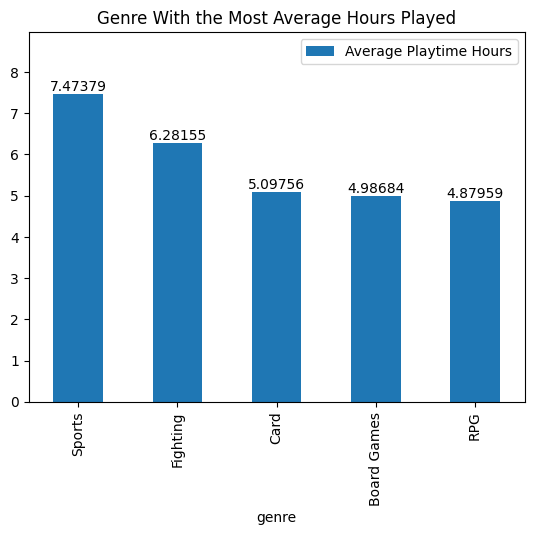

In [137]:
plot = hours_played.head().plot(kind='bar', title='Genre With the Most Average Hours Played')

# Loops through every bar to add a label above it
for bar in plot.containers:
    plot.bar_label(bar)

# Adds space above the bars for readability
plot.set_ylim(0, hours_played['avg_playtime_hours'].iloc[0] * 1.2)
plt.legend(['Average Playtime Hours'])
plt.show()

#### 2. Do games with higher platform counts have a higher completion status

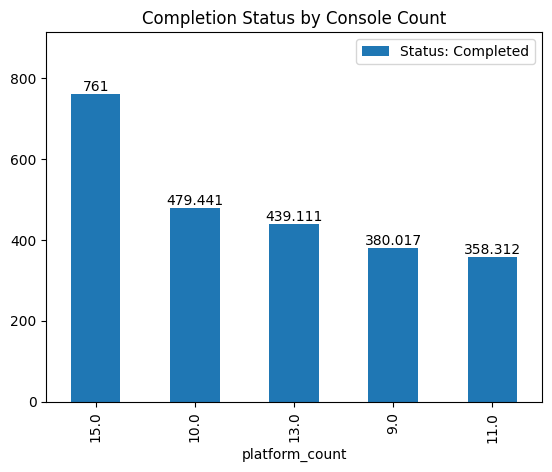

In [138]:
plot = completion_by_platform_count.head().plot(kind='bar', title='Completion Status by Console Count')

for bar in plot.containers:
    plot.bar_label(bar)

plot.set_ylim(0, completion_by_platform_count['status_beaten'].iloc[0] * 1.2)
plt.legend(['Status: Completed'])
plt.show()

#### 3. Do multiplayer, singleplayer, or single & multiplayer games have a higher metacritic score

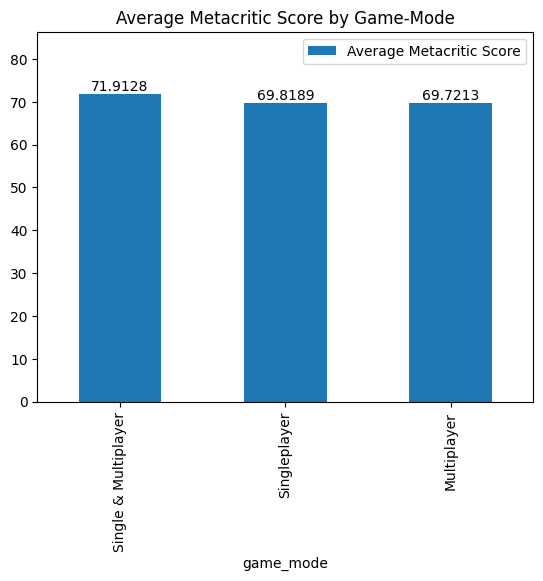

In [139]:
plot = score_by_game_mode.head().plot(kind='bar', title='Average Metacritic Score by Game-Mode')

for bar in plot.containers:
    plot.bar_label(bar)

plot.set_ylim(0, score_by_game_mode['metacritic'].iloc[0] * 1.2)
plt.legend(['Average Metacritic Score'])
plt.show()

#### 4. What decade has the highest rated games

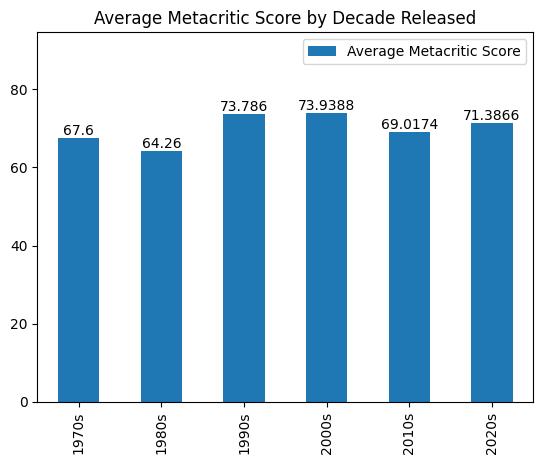

In [140]:
release.sort_values(['release_year'], ascending=True, inplace=True)

plot = release['metacritic'].plot(kind='bar', title='Average Metacritic Score by Decade Released')

for bar in plot.containers:
    plot.bar_label(bar)

plot.set_ylim(0, release['metacritic'].iloc[0] * 1.4)
plt.legend(['Average Metacritic Score'])
plt.show()

# Melissa Weitekamp Notebook

### Questions & Goals:
1. What genre has the most average hours played?
2. Do games with higher platform counts have higher completion status?
3. Do multiplayer, singleplayer, or single & multiplayer games have higher metacritic scores?
4. What decades had the highest rated games?
5. What was the shift in game’s genres and themes over the decades?
6. Predict user ratings of games based on metadata

### Data Loading & Cleaning

In [141]:
import pandas as pd
import numpy as np

In [142]:
# Load the raw dataset and output first five rows
df_raw = pd.read_csv('Ultimate_Games_Dataset.csv')
display(df_raw.head())

,serial_no,game_id,title,release_date,release_year,all_genres,theme,art_style,view_dimension,game_mode,...,cover_image_url,official_website,url_slug,description_clean,popularity_score,engagement_score,decade,is_multi_platform,rating_tier,metacritic_tier
0,1,3498,Grand Theft Auto V,2013-09-17,2013.0,Action,Crime,Realistic,3D,Single & Multiplayer,...,https://media.rawg.io/media/games/20a/20aa03a1...,http://www.rockstargames.com/V/,grand-theft-auto-v,"Rockstar Games went bigger, since their previo...",96.28,21.75,2010s,1,excellent,universal_acclaim
1,2,3328,The Witcher 3: Wild Hunt,2015-05-18,2015.0,Action|RPG,Fantasy,Realistic,3D,Singleplayer,...,https://media.rawg.io/media/games/618/618c2031...,https://thewitcher.com/en/witcher3,the-witcher-3-wild-hunt,"The third game in a series, it holds nothing b...",95.81,17.19,2010s,1,masterpiece,universal_acclaim
2,3,4200,Portal 2,2011-04-18,2011.0,Shooter|Puzzle,Sci-Fi,Realistic,3D,Single & Multiplayer,...,https://media.rawg.io/media/games/2ba/2bac0e87...,http://www.thinkwithportals.com/,portal-2,Portal 2 is a first-person puzzle game develop...,91.26,15.24,2010s,1,masterpiece,universal_acclaim
3,4,4291,Counter-Strike: Global Offensive,2012-08-21,2012.0,Shooter,Horror,Realistic,3D,Multiplayer,...,https://media.rawg.io/media/games/736/73619bd3...,http://blog.counter-strike.net/,counter-strike-global-offensive,Counter-Strike is a multiplayer phenomenon in ...,73.56,8.79,2010s,1,good,generally_favorable
4,5,5286,Tomb Raider (2013),2013-03-05,2013.0,Action,Adventure,Realistic,3D,Single & Multiplayer,...,https://media.rawg.io/media/games/021/021c4e21...,http://www.tombraider.com,tomb-raider,A cinematic revival of the series in its actio...,76.54,13.77,2010s,1,excellent,generally_favorable


In [143]:
# Get count, data type, and statistical summary of each column
df_raw.info()

print("\n\nStatistical summary of raw dataset: \n")
df_raw.describe()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 43 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   serial_no           15000 non-null  int64  
 1   game_id             15000 non-null  int64  
 2   title               15000 non-null  str    
 3   release_date        15000 non-null  str    
 4   release_year        15000 non-null  float64
 5   all_genres          15000 non-null  str    
 6   theme               15000 non-null  str    
 7   art_style           15000 non-null  str    
 8   view_dimension      15000 non-null  str    
 9   game_mode           15000 non-null  str    
 10  is_multiplayer      15000 non-null  int64  
 11  controls            15000 non-null  str    
 12  developers          15000 non-null  str    
 13  publishers          15000 non-null  str    
 14  all_platforms       15000 non-null  str    
 15  platform_count      15000 non-null  float64
 16  esrb_rating    

,serial_no,game_id,release_year,is_multiplayer,platform_count,user_rating,metacritic,ratings_count,reviews_count,library_count,...,game_series_count,status_owned,status_beaten,status_playing,status_dropped,status_toplay,status_yet,popularity_score,engagement_score,is_multi_platform
count,15000.000000,1.500000e+04,15000.000000,15000.000000,15000.000000,14613.000000,14114.000000,15000.000000,15000.000000,15000.000000,...,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,7500.500000,2.497638e+05,2015.643267,0.247133,2.604800,3.274654,70.719265,105.165733,104.721933,745.553400,...,1.897133,569.275933,73.721333,8.292533,36.340133,24.528000,36.691067,24.933877,3.813943,0.600333
std,4330.271354,3.421321e+05,6.514203,0.431359,1.869131,0.708470,8.136159,319.697866,320.632844,1506.652519,...,5.958645,1079.416333,276.541649,32.800122,103.728662,77.747554,79.647606,10.233402,5.679271,0.489846
min,1.000000,2.000000e+00,1979.000000,0.000000,1.000000,1.000000,23.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.610000,0.000000,0.000000
25%,3750.750000,1.474325e+04,2014.000000,0.000000,1.000000,2.810000,66.000000,2.000000,1.000000,11.000000,...,0.000000,9.000000,1.000000,0.000000,1.000000,1.000000,1.000000,20.230000,0.450000,0.000000
50%,7500.500000,2.887100e+04,2016.000000,0.000000,2.000000,3.430000,70.000000,17.000000,15.000000,281.000000,...,0.000000,224.500000,5.000000,2.000000,5.000000,4.000000,9.000000,26.500000,1.825000,1.000000
75%,11250.250000,4.848145e+05,2020.000000,0.000000,3.000000,3.800000,75.100000,68.000000,68.000000,743.000000,...,0.000000,604.000000,30.000000,5.000000,26.000000,15.000000,35.000000,30.800000,4.250000,1.000000
max,15000.000000,1.006908e+06,2026.000000,1.000000,22.000000,5.000000,99.000000,7153.000000,7268.000000,22126.000000,...,77.000000,14089.000000,6283.000000,949.000000,2101.000000,2440.000000,1181.000000,96.280000,41.930000,1.000000


In [144]:
# Create dataframe with necessary columns
df = df_raw[['title', 'release_year', 'decade', 'all_genres', 'theme', 'game_mode', 
             'is_multiplayer', 'all_platforms', 'platform_count',
             'user_rating', 'metacritic', 'avg_playtime_hours', 'status_beaten']]

# Locate missing values
print(df.isnull().sum())

title                   0
release_year            0
decade                  0
all_genres              0
theme                   0
game_mode               0
is_multiplayer          0
all_platforms           0
platform_count          0
user_rating           387
metacritic            886
avg_playtime_hours      0
status_beaten           0
dtype: int64


In [145]:
# Handle missing values for later plotting (playtime hours missing and metacritic & user rating scores for Q3, Q4, & Q6)
non_zero_playtime = df[df['avg_playtime_hours'] > 0]

df_clean = df.dropna(subset=['metacritic', 'user_rating'])

# Removing games without specified game modes for Q3
df_clean = df_clean[df_clean.game_mode != 'Not Specified']

# Display cleaned rows
print(f"Original: {len(df)} rows")
print(f"After dropping: {len(df_clean)} rows")

Original: 15000 rows
After dropping: 12994 rows


In [146]:
# Display clean dataframe head
print("\n\nStatistical summary of cleaned dataset: \n")
df_clean.describe()



Statistical summary of cleaned dataset: 



,release_year,is_multiplayer,platform_count,user_rating,metacritic,avg_playtime_hours,status_beaten
count,12994.000000,12994.000000,12994.000000,12994.000000,12994.000000,12994.000000,12994.000000
mean,2016.026705,0.285286,2.628213,3.248599,70.295144,3.744651,71.899723
std,6.380033,0.451568,1.886548,0.703504,7.705511,8.061111,278.226379
min,1979.000000,0.000000,1.000000,1.000000,23.000000,1.000000,0.000000
25%,2014.000000,0.000000,1.000000,2.790000,65.800000,1.000000,1.000000
50%,2017.000000,0.000000,2.000000,3.400000,69.600000,3.000000,6.000000
75%,2021.000000,1.000000,3.000000,3.780000,74.500000,4.000000,27.000000
max,2026.000000,1.000000,22.000000,5.000000,99.000000,367.000000,6283.000000


### Data Wrangling, Aggregation, & Plotting

In [147]:
import matplotlib.pyplot as plt

#### Question 1: What genre has the most average hours played

genre
Sports                   7.473795
Fighting                 6.281553
Card                     5.097561
Board Games              4.986842
RPG                      4.879594
Family                   4.587413
Shooter                  4.461806
Platformer               4.461454
Arcade                   4.448598
Educational              4.247191
Racing                   4.208602
Adventure                4.049741
Action                   4.018377
Simulation               3.837476
Massively Multiplayer    3.600478
Strategy                 3.588874
Puzzle                   3.308017
Indie                    3.210682
Casual                   3.208934
Name: avg_playtime_hours, dtype: float64

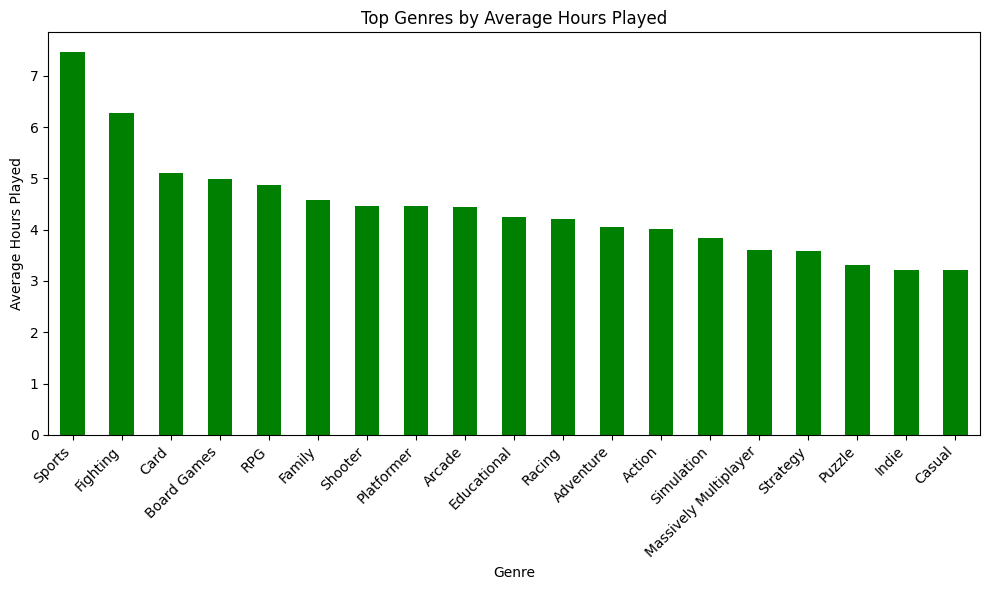

In [148]:
# Split genres of 'all_genres' into separate rows with .explode()
df_genres = non_zero_playtime.assign(genre=non_zero_playtime['all_genres'].str.split('|')).explode('genre')

# Calculate average playtime and display
genres_hours = df_genres[['genre', 'avg_playtime_hours']]
avg_hours = genres_hours.groupby('genre')['avg_playtime_hours'].mean().sort_values(ascending=False)

# Display results
display(avg_hours)

# Plot the values
plt.figure(figsize=(10, 6))
avg_hours.plot(kind='bar', color='green')
plt.title('Top Genres by Average Hours Played')
plt.ylabel('Average Hours Played')
plt.xlabel('Genre')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

Observation:
- Sport games have the most average hours (around 7.47 hours on average)
- Casual games have the least (around 3.21 on average)

#### Question 2: Do games with higher platform counts have higher completion status?

Original: 15000 rows
platform_count
1.0      19.423353
2.0      51.614198
3.0      67.450439
4.0     125.171363
5.0     163.050104
6.0     219.636905
7.0     311.618557
8.0     269.359281
9.0     358.453125
10.0    447.027027
11.0    318.500000
12.0    222.000000
13.0    420.900000
14.0     36.000000
15.0    295.666667
17.0    231.000000
22.0    195.000000
Name: status_beaten, dtype: float64


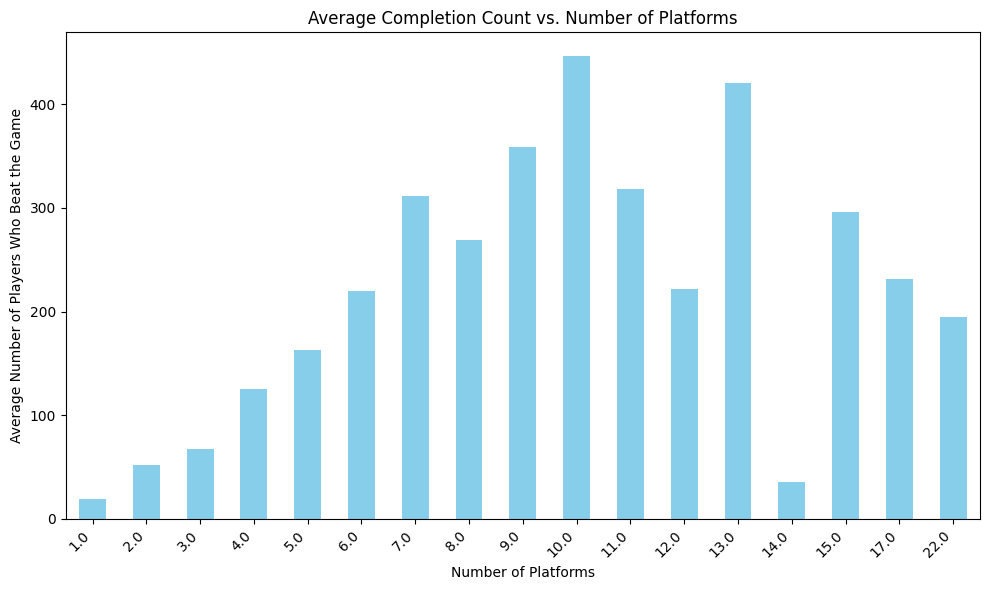

In [153]:
# Group platform by completion status and get the average

print(f"Original: {len(df)} rows")

beaten_by_platform = df[['platform_count', 'status_beaten']]
platform_completion = beaten_by_platform.groupby('platform_count')['status_beaten'].mean()

print(platform_completion)

# Plot the values
plt.figure(figsize=(10, 6))
platform_completion.plot(kind='bar', color='skyblue')
plt.title('Average Completion Count vs. Number of Platforms')
plt.ylabel('Average Number of Players Who Beat the Game')
plt.xlabel('Number of Platforms')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

Observation:
- On average, the more platform releases a game has, the more likely the game will be played and beaten (positive trend)

#### Question 3: Do multiplayer, singleplayer, or single & multiplayer games have higher metacritic scores?

game_mode
Single & Multiplayer    71.912847
Singleplayer            69.818895
Multiplayer             69.721330
Name: metacritic, dtype: float64


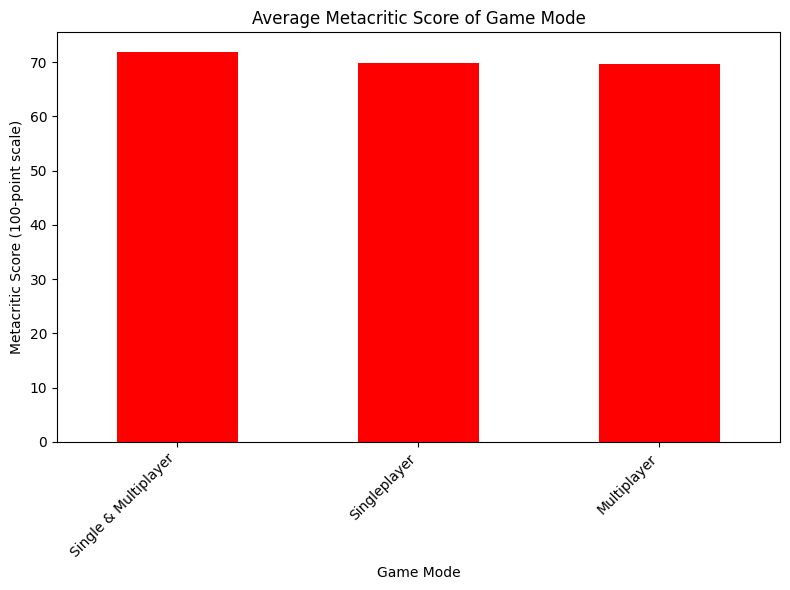

In [150]:
# Create dataframe with needed columns from cleaned dataframe
gamemode_score = df_clean[['game_mode', 'metacritic']]

# Calculate average metacritic score for each game mode
avg_gamemode_by_score = gamemode_score.groupby('game_mode')['metacritic'].mean().sort_values(ascending=False)

# Display average
print(avg_gamemode_by_score)

# Plot the values
plt.figure(figsize=(8, 6))
avg_gamemode_by_score.plot(kind='bar', color='red')
plt.title('Average Metacritic Score of Game Mode')
plt.ylabel('Metacritic Score (100-point scale)')
plt.xlabel('Game Mode')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

Observation:
- Scores are close in range for all three game mode types. Games that have both game modes do have a slightly higher score.

#### Question 4: What decades had the highest rated games?

Average Metracritic Score per Decade (100-point scale) :
decade
1970s    67.600000
1980s    64.260000
1990s    73.786041
2000s    73.938793
2010s    69.017445
2020s    71.386649
Name: metacritic, dtype: float64

Average User Rating Score per Decade (5-point scale):
decade
1970s    2.090000
1980s    3.572364
1990s    3.663782
2000s    3.485163
2010s    3.001743
2020s    3.581884
Name: user_rating, dtype: float64



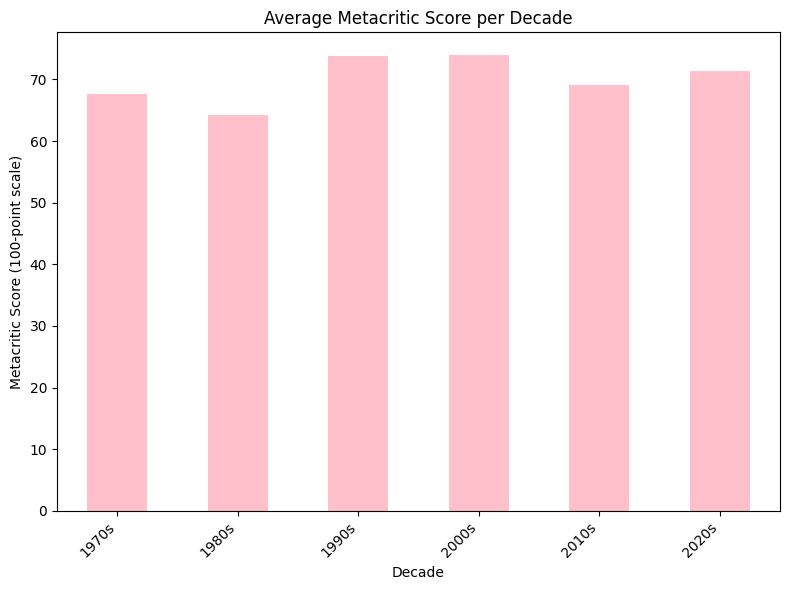

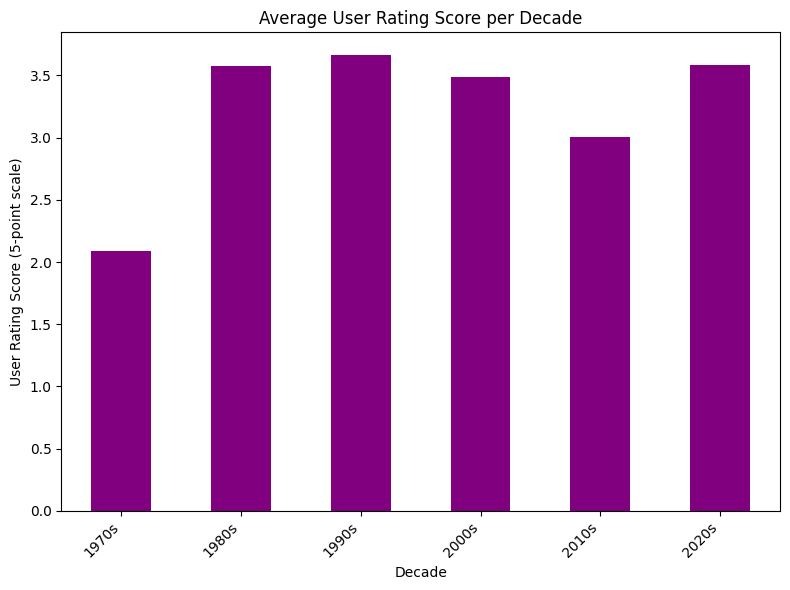

In [151]:
# Create dataframe with needed columns from cleaned dataframe
decade_rating = df_clean[['decade', 'metacritic', 'user_rating']]

# Calculate average metacritic score for each game mode
decade_highest_meta_rating = decade_rating.groupby('decade')['metacritic'].mean()
decade_highest_user_rating = decade_rating.groupby('decade')['user_rating'].mean()

# Display average
print(f"Average Metracritic Score per Decade (100-point scale) :\n{decade_highest_meta_rating}\n")
print(f"Average User Rating Score per Decade (5-point scale):\n{decade_highest_user_rating}\n")

# Plot the values
plt.figure(figsize=(8, 6))
decade_highest_meta_rating.plot(kind='bar', color='pink')
plt.title('Average Metacritic Score per Decade')
plt.ylabel('Metacritic Score (100-point scale)')
plt.xlabel('Decade')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.figure(figsize=(8, 6))
decade_highest_user_rating.plot(kind='bar', color='purple')
plt.title('Average User Rating Score per Decade')
plt.ylabel('User Rating Score (5-point scale)')
plt.xlabel('Decade')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

Observation:
- The 2000s had the highest metacritic rating games on average with 1990s close in score.
- The 2020s is close in critical reception for metacritic scoring average
- The 1990s had the highest average user rating for games, with 1980s in 2nd, and 2000s in 3rd.

### Trend & Prediction Modeling

In [152]:
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline 

#### Question 5: What was the shift in game’s genres and themes over the decades?

genre,Action,Adventure,Arcade,Board Games,Card,Casual,Educational,Family,Fighting,Indie,Massively Multiplayer,Platformer,Puzzle,RPG,Racing,Shooter,Simulation,Sports,Strategy
decade,,,,,,,,,,,,,,,,,,,
1970s,0.000000,0.250000,0.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.250000,0.000000,0.250000,0.000000,0.000000,0.000000
1980s,0.277778,0.180556,0.090278,0.000000,0.000000,0.027778,0.000000,0.006944,0.013889,0.041667,0.006944,0.145833,0.034722,0.069444,0.006944,0.020833,0.027778,0.020833,0.027778
1990s,0.241379,0.154158,0.074037,0.003043,0.002028,0.053753,0.028398,0.002028,0.025355,0.022312,0.004057,0.065923,0.025355,0.072008,0.029412,0.087221,0.031440,0.004057,0.074037
2000s,0.252901,0.131058,0.053584,0.002389,0.002048,0.054266,0.003413,0.010580,0.014334,0.060751,0.006826,0.021843,0.025256,0.092491,0.026621,0.081911,0.040956,0.016724,0.102048
2010s,0.161868,0.157872,0.018458,0.003301,0.002562,0.107926,0.002215,0.004647,0.005385,0.216417,0.016808,0.010771,0.023670,0.081911,0.015027,0.019197,0.064712,0.017329,0.069924
2020s,0.081205,0.196493,0.002338,0.000270,0.001888,0.170504,0.000629,0.001169,0.002698,0.225809,0.005126,0.008363,0.009353,0.115917,0.005126,0.012230,0.103777,0.007284,0.049820


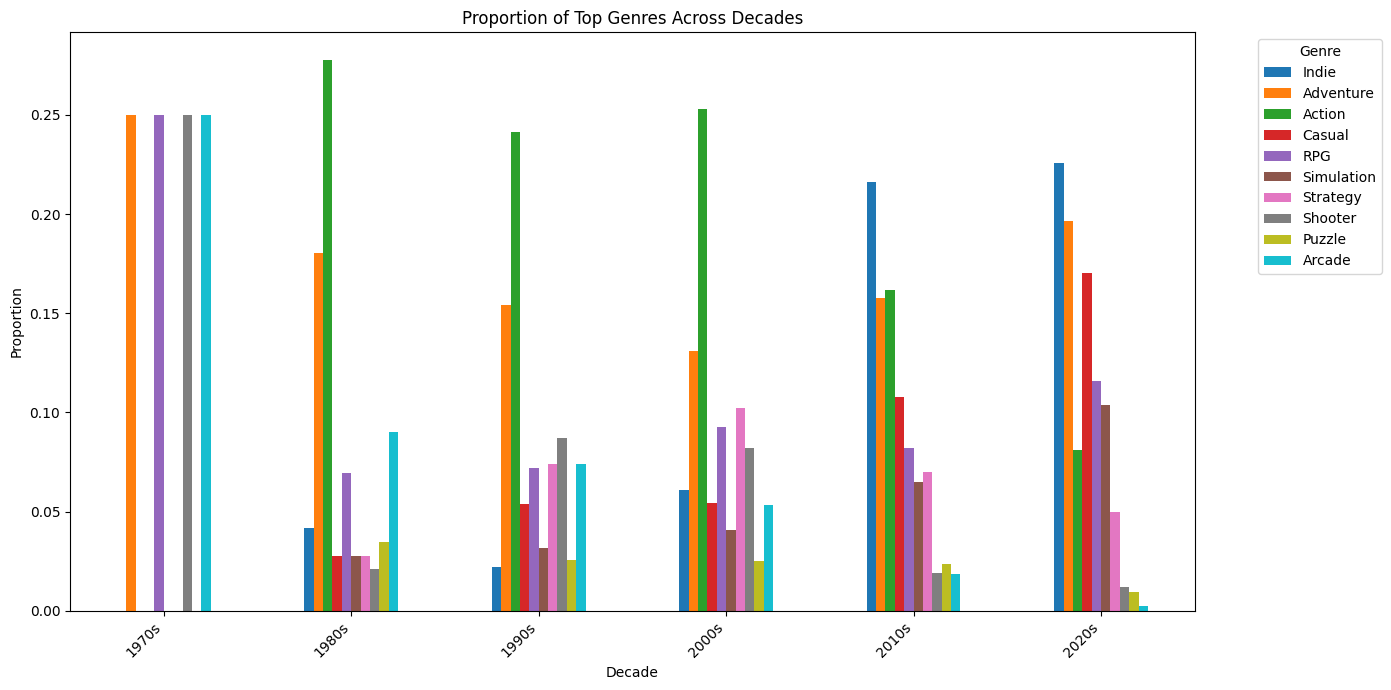

In [90]:
# Split genres of 'all_genres' into separate rows with .explode() while .reset_index() removes duplicate indexes
df_genres_over_time = (df.assign(genre=df['all_genres'].str.split('|')).explode('genre').reset_index(drop=True)) 

# Create a cross tabulation of top genres per decade
genre_decade_crosstab = pd.crosstab(df_genres_over_time['decade'], df_genres_over_time['genre'], normalize='index')

# Display the frequency table
display(genre_decade_crosstab)

# Plot the top 10 genres across decades
top_genres = df_genres_over_time['genre'].value_counts().head(10).index
genre_decade_crosstab_top = genre_decade_crosstab[top_genres]

fig, ax = plt.subplots(figsize=(14, 7))
genre_decade_crosstab_top.plot(kind='bar', ax=ax)
plt.title('Proportion of Top Genres Across Decades')
plt.xlabel('Decade')
plt.ylabel('Proportion')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Genre', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

Observations:
- The 1970s had an even mix of Adventure, RPG, Shooter, and Arcade games
- The 1980s had a big rise in Action based games and it stayed till the 2000s
- By 2010s, there was a rise in Indie games. Adventure and Action games were behind it.
- The 2020s had a steady proportion of indie games overall alongisde Adventure. Casual games rose this decade.

theme,Adventure,Comedy,Crime,Fantasy,General,Historical,Horror,Mythology,Not Specified,Post-Apocalyptic,Sci-Fi,Sports
decade,,,,,,,,,,,,
1970s,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000,0.000000,0.500000,0.000000,0.000000,0.000000
1980s,0.072464,0.028986,0.000000,0.202899,0.260870,0.057971,0.028986,0.028986,0.115942,0.028986,0.159420,0.014493
1990s,0.034188,0.027778,0.042735,0.113248,0.168803,0.051282,0.141026,0.021368,0.100427,0.019231,0.256410,0.023504
2000s,0.051496,0.013222,0.044537,0.145442,0.149617,0.092554,0.135699,0.015310,0.072373,0.010438,0.242867,0.026444
2010s,0.035235,0.026135,0.035352,0.137674,0.177692,0.041419,0.179676,0.006534,0.081321,0.014934,0.246996,0.017034
2020s,0.017965,0.095217,0.034359,0.236470,0.252639,0.029868,0.136762,0.005614,0.046261,0.015046,0.126432,0.003369


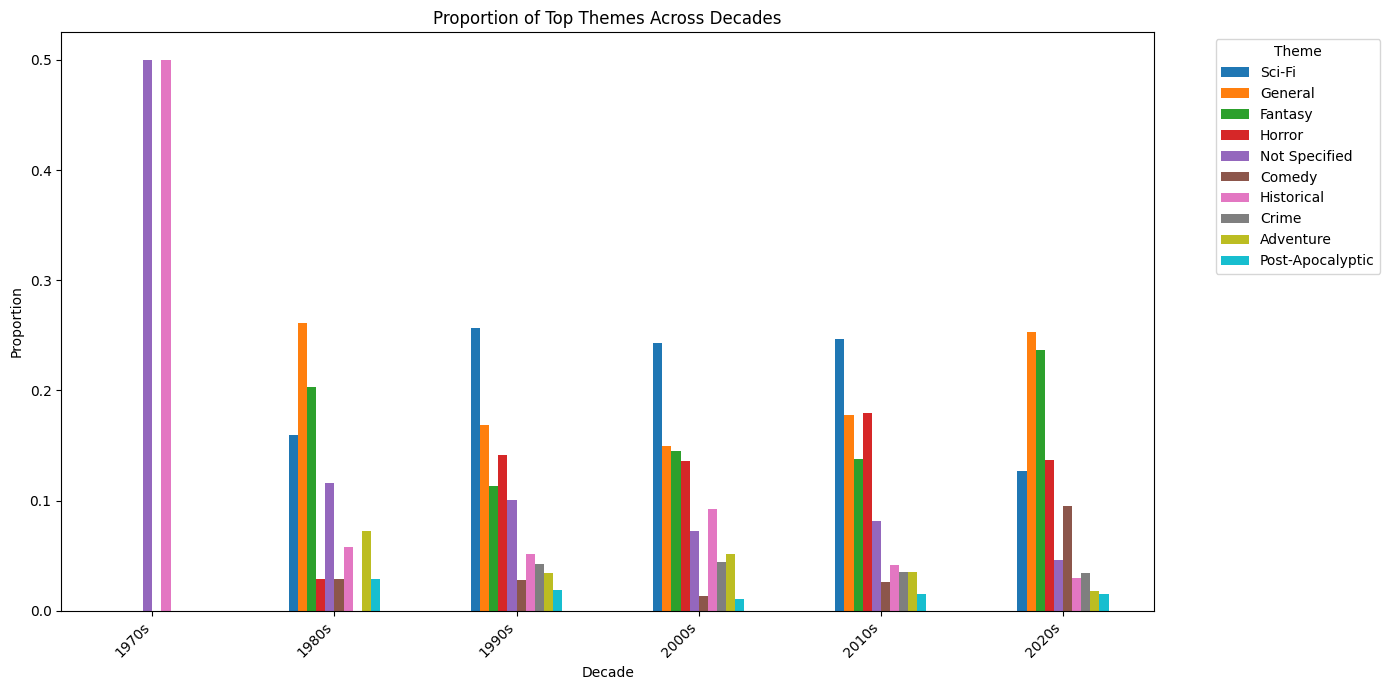

In [91]:
# Split themes into separate rows with .explode()
df_themes_over_time = (df.assign(genre=df['theme'].str.split('|')).explode('theme').reset_index(drop=True))

# Handle NaN themes
df_themes_over_time = df_themes_over_time.dropna(subset=['theme'])

# Create a cross tabulation of top themes per decade
theme_decade_crosstab = pd.crosstab(df_themes_over_time['decade'], df_themes_over_time['theme'], normalize='index')

# Display the frequency table
display(theme_decade_crosstab)

# Plot the top 10 genres across decades
top_genres = df_themes_over_time['theme'].value_counts().head(10).index
genre_theme_crosstab_top = theme_decade_crosstab[top_genres]

fig, ax = plt.subplots(figsize=(14, 7))
genre_theme_crosstab_top.plot(kind='bar', ax=ax)
plt.title('Proportion of Top Themes Across Decades')
plt.xlabel('Decade')
plt.ylabel('Proportion')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Theme', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

Observations:
- The 1970s themes were evenly Not Specified or Historical
- The 1980s had a rise in General and Fantasy themes
- The 1990s had a rise in Sci-Fi themed games.
- The 1990s and 2000s had a similar proportion of themes to 1980s. Fantasy games steady rose over the two decades.
- By 2010s, Horror and General themed games increased in proportion, but Sci-Fi was still the top theme.
- The 2020s had a decrease in Sci-Fi. General and Fantasy were the top themes with Horror behind it.

#### Question 6: Predict user ratings of games based on metadata

In [92]:
# Get clean data for modeling by dropping NaN and Null values
df_model = df.dropna(subset=['user_rating', 'metacritic', 'avg_playtime_hours']).copy()

# Convert decade to numeric value
df_model['decade_numeric'] = df_model['decade'].str.replace('s', '').astype(float)

# Select metadata features
features = ['avg_playtime_hours', 'platform_count', 'metacritic', 'decade_numeric', 'all_genres', 'game_mode', 'is_multiplayer']

# One-hot encoding (get_dummies) for categorical features (ie. genres, gamemode, multiplayer)
dummies_genres = pd.get_dummies(df_model['all_genres'], prefix='genre')
dummies_mode = pd.get_dummies(df_model['game_mode'], prefix='mode')
dummies_multiplayer = pd.get_dummies(df_model['is_multiplayer'], prefix='multi')

# Set X by concating features with dummies and set Y
X =  pd.concat([df_model[['avg_playtime_hours', 'platform_count', 'metacritic', 'decade_numeric']], 
                dummies_genres, dummies_mode, dummies_multiplayer], axis=1)
y = df_model['user_rating']

# Split the dataset into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# RandomForestRegressor can predict continuous numerical values by averaging predictions from multiple decision trees
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)    #Fit the model to the training data

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [93]:
# Evaluation metrics
y_pred = model.predict(X_test) #Make predictions on the testing data

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.4f}")
print(f"Root Mean Squared Error: {rmse:.4f}")
print(f"Mean Absolute Error: {mae:.4f}")
print(f"R-Squared: {r2:.4f}")

Mean Squared Error: 0.1884
Root Mean Squared Error: 0.4341
Mean Absolute Error: 0.3185
R-Squared: 0.6056


Observation:
- RMSE (Root Mean Squared Error) has a larger value than MSE, so there are some outliers but nothing concerning.
- MAE (Mean Absolute Error) is relatively low, indicating an accurate model with the absolute differences between forecasted and actual values being close.
- R-Sqaure is 0.6056, or 60.56%. R-Squared represents how well independent variables predict the dependent variable; it's larger value indicts an accurate model.

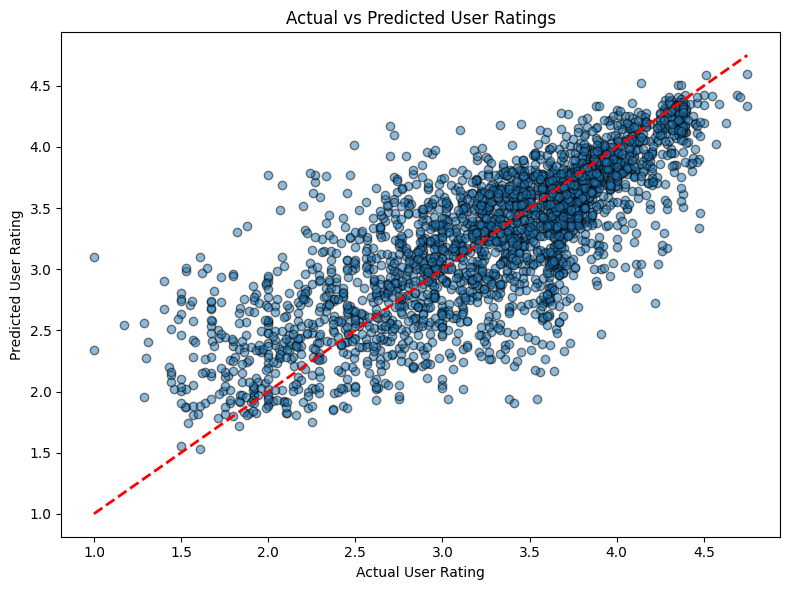

In [94]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5, edgecolors='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual User Rating')
plt.ylabel('Predicted User Rating')
plt.title('Actual vs Predicted User Ratings')
plt.tight_layout()

Observations:
- Scatterplot shows the correlation of user ratings being close to predicted user ratings. The evaluated metrics support the accuracy of the model.